# Predictive Maintenance & Industrial Anomaly Detection: walkthrough

**Business question:** a machine that breaks unexpectedly stops the line. Can sensor data tell us *which* runs are about to fail, and *how early* a developing problem becomes visible, so maintenance can be planned instead of reactive?

1. **Failure prediction** (supervised): 10,000 milling-machine runs with labelled failures (AI4I 2020).
2. **Early warning** (unsupervised): 11 weeks of a real industrial machine's temperature sensor, no labels used to build the detectors (NAB).

Every number below comes from the scripts in `src/`. This notebook runs them and explains the results.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from data import load_ai4i, FAILURE_MODES
pd.set_option("display.width", 140)

## Part 1: Failure prediction
### The data

In [2]:
df = load_ai4i()
print(f"{len(df):,} runs, {df.failure.sum()} machine failures ({df.failure.mean():.1%})")
df[["product_id", "type", "air_temp_k", "process_temp_k", "speed_rpm", "torque_nm", "tool_wear_min", "failure"]].head()

10,000 runs, 339 machine failures (3.4%)


,product_id,type,air_temp_k,process_temp_k,speed_rpm,torque_nm,tool_wear_min,failure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0


Failures are rare (3.4%), so plain accuracy would be misleading: a model that never predicts a failure would be 96.6% "accurate". The project therefore uses **precision** (how many alarms are real), **recall** (how many failures are caught) and **cost**.

In [3]:
modes = pd.DataFrame({"failure mode": FAILURE_MODES.values(),
                      "runs flagged": [int(df[c].sum()) for c in FAILURE_MODES],
                      "of which recorded as machine failure": [int(((df[c] == 1) & (df.failure == 1)).sum()) for c in FAILURE_MODES]},
                     index=FAILURE_MODES.keys())
modes

,failure mode,runs flagged,of which recorded as machine failure
TWF,Tool wear failure,46,46
HDF,Heat dissipation failure,115,115
PWF,Power failure,95,95
OSF,Overstrain failure,98,98
RNF,Random failure,19,1


**Data quality note:** 18 of the 19 *random failure* flags sit on runs that are **not** recorded as a machine failure. They are treated as noise, not as failures to predict.

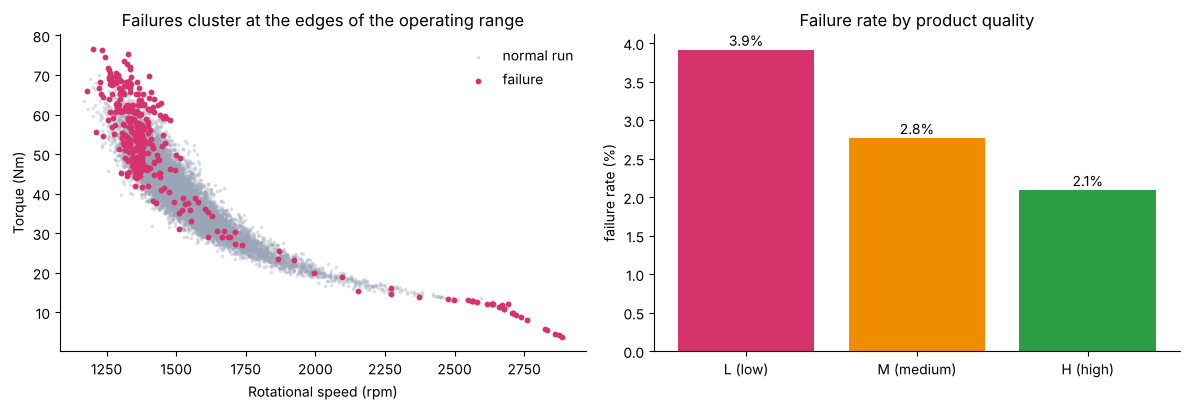

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ok, bad = df[df.failure == 0], df[df.failure == 1]
axes[0].scatter(ok.speed_rpm, ok.torque_nm, s=3, alpha=0.25, color="#9aa5b8", label="normal run")
axes[0].scatter(bad.speed_rpm, bad.torque_nm, s=10, color="#d6336c", label="failure")
axes[0].set(xlabel="Rotational speed (rpm)", ylabel="Torque (Nm)", title="Failures cluster at the edges of the operating range")
axes[0].legend(frameon=False)
rate = df.groupby("type").failure.mean().reindex(["L", "M", "H"]) * 100
axes[1].bar(["L (low)", "M (medium)", "H (high)"], rate, color=["#d6336c", "#f08c00", "#2e9e44"])
axes[1].set(ylabel="failure rate (%)", title="Failure rate by product quality")
for i, v in enumerate(rate): axes[1].text(i, v + 0.05, f"{v:.1f}%", ha="center")
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("assets/eda_operating_range.png", dpi=150); plt.show()

Failures sit at the **extremes**: very low torque at high speed (too little power), very high torque at low speed (overstrain or too much power). That suggests physics-based features: **power** = torque × angular speed, **strain** = tool wear × torque, and the **temperature difference** between process and air (heat dissipation).

### Train, compare and choose
The script holds out 20% of runs as an untouched test set, compares models with 5-fold cross-validation, picks the alarm threshold that minimises maintenance cost (`configs/costs.yaml`), and evaluates once on the test set.

In [5]:
!python src/failure_prediction.py

Train: 8,000 runs (271 failures) | Test: 2,000 runs (68 failures)


  Logistic regression                      PR-AUC 0.455


  Random forest                            PR-AUC 0.893


  Gradient boosting (raw sensors only)     PR-AUC 0.792


  Gradient boosting                        PR-AUC 0.875


Best model (cross-validated PR-AUC): Random forest
Cost-optimal threshold: 0.34 | planned tool change: 205 min


Break-even breakdown cost (test set): EUR 10,750



Cross-validated comparison (training set):
                                model  PR-AUC  ROC-AUC  Recall  Precision    F1
Rule of thumb: change tool at 200 min     NaN      NaN   0.358      0.155 0.216
                  Logistic regression   0.455    0.922   0.841      0.161 0.271
                        Random forest   0.893    0.977   0.786      0.964 0.866
 Gradient boosting (raw sensors only)   0.792    0.967   0.638      0.836 0.724
                    Gradient boosting   0.875    0.968   0.801      0.948 0.868

Test set: {'PR-AUC': 0.88, 'ROC-AUC': 0.979, 'Recall': 0.853, 'Precision': 0.879, 'F1': 0.866}

Cost comparison (test set):
                                 strategy  failures_caught  failures_missed  false_alarms  total_cost_eur  cost_per_1000_runs_eur  saving_vs_run_to_failure
           Run to failure (no prediction)                0               68             0          680000                  340000                     0.000
    Rule of thumb: change tool at 200 m

In [6]:
pd.read_csv('results/model_comparison_cv.csv')

,model,PR-AUC,ROC-AUC,Recall,Precision,F1
0,Rule of thumb: change tool at 200 min,NaN,NaN,0.358,0.155,0.216
1,Logistic regression,0.455,0.922,0.841,0.161,0.271
2,Random forest,0.893,0.977,0.786,0.964,0.866
3,Gradient boosting (raw sensors only),0.792,0.967,0.638,0.836,0.724
4,Gradient boosting,0.875,0.968,0.801,0.948,0.868


Adding the three engineered features lifts the same gradient-boosting model from **0.79 to 0.88 PR-AUC**: domain knowledge beats more data here. The random forest is best overall (0.89).

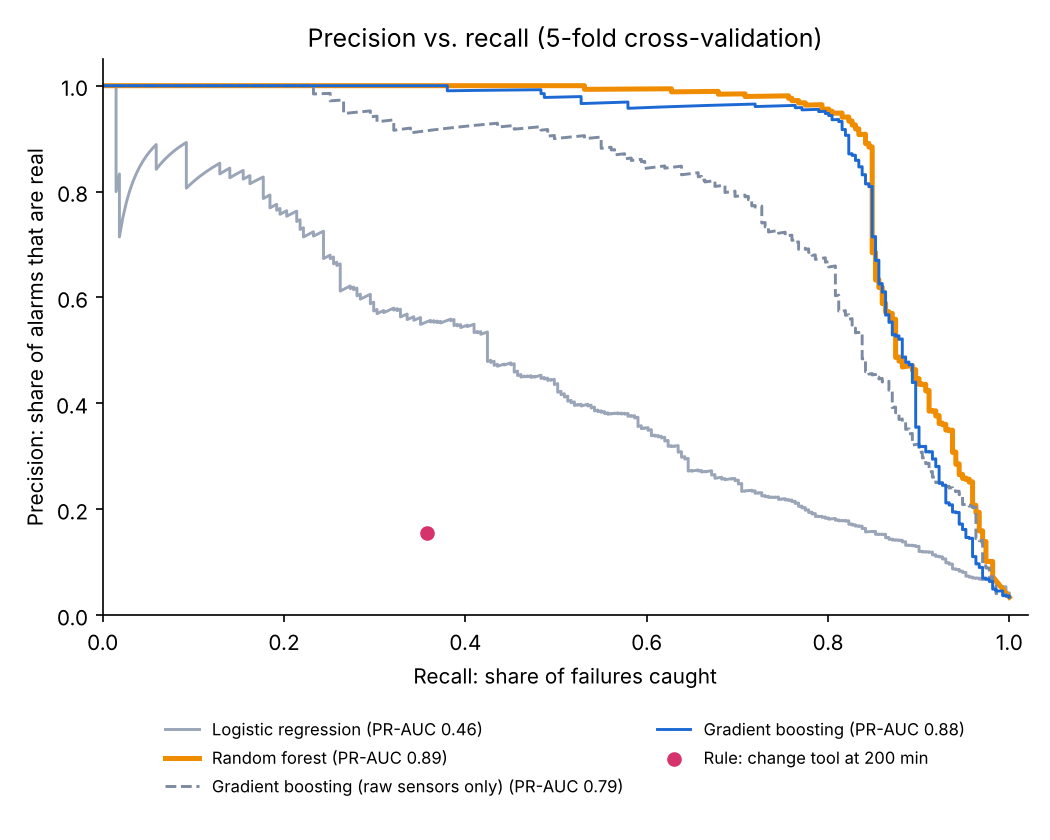

In [7]:
display(Image('assets/pr_curves.png', width=620))

### What does it save?

In [8]:
pd.read_csv('results/cost_comparison_test.csv')

,strategy,failures_caught,failures_missed,false_alarms,total_cost_eur,cost_per_1000_runs_eur,saving_vs_run_to_failure
0,Run to failure (no prediction),0,68,0,680000,340000,0.000
1,Rule of thumb: change tool at 200 min,26,42,149,546500,273250,0.196
2,"ML model, default threshold 0.50",55,13,3,241500,120750,0.645
3,"ML model, cost-optimal threshold 0.34",58,10,8,220000,110000,0.676
4,ML model + planned tool change at 205 min,64,4,113,224500,112250,0.670


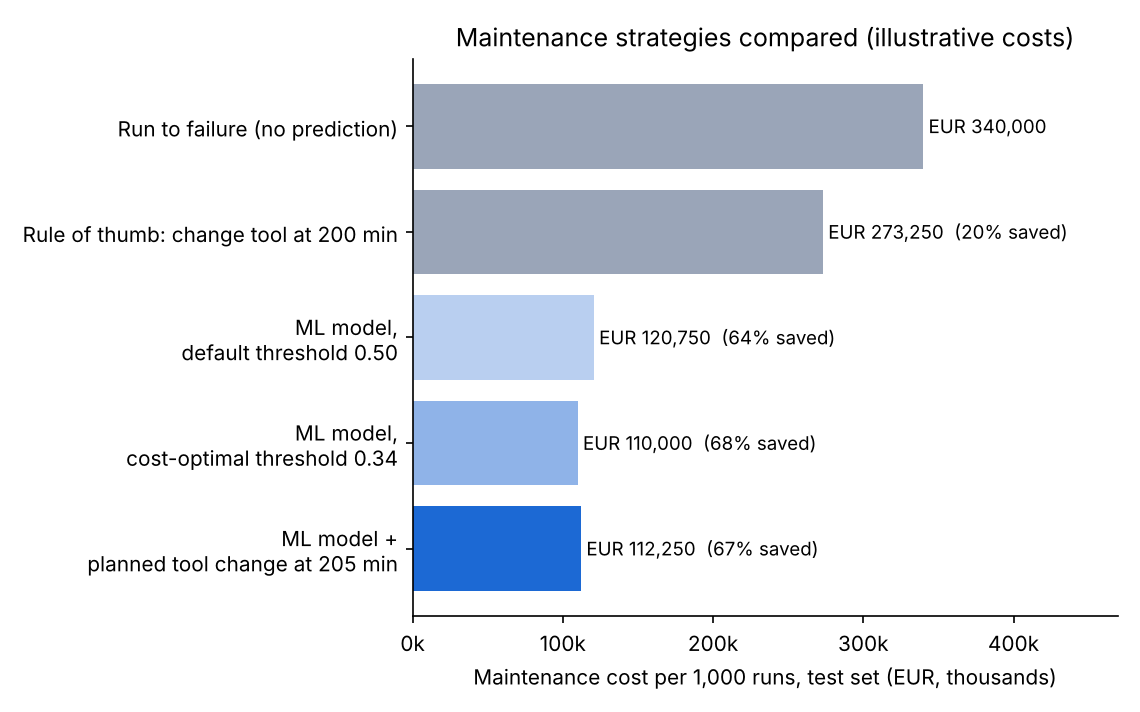

In [9]:
display(Image('assets/cost_comparison.png', width=720))

Which strategy is best depends on what a breakdown really costs. The planned tool change catches more failures but adds inspections:

In [10]:
pd.read_csv('results/cost_sensitivity_test.csv')

,unplanned_failure_cost_eur,model_only_eur,model_plus_tool_change_eur,cheaper
0,5000,170000,204500,model only
1,10000,220000,224500,model only
2,20000,320000,264500,model + tool change
3,50000,620000,384500,model + tool change
4,100000,1120000,584500,model + tool change


In [11]:
pd.read_csv('results/failure_mode_recall_test.csv')

,failure_mode,code,failures_in_test,caught_model,recall_model,caught_model_plus_tool_change,recall_model_plus_tool_change
0,Tool wear failure,TWF,10,2,0.2,7,0.7
1,Heat dissipation failure,HDF,29,29,1.0,29,1.0
2,Power failure,PWF,13,13,1.0,13,1.0
3,Overstrain failure,OSF,16,16,1.0,16,1.0
4,Random failure,RNF,0,0,NaN,0,NaN


Heat, power and overstrain failures are caught **100%** of the time. Tool-wear failures happen at a random point between ~200 and 240 minutes, so the sensors can't see them coming. A planned tool change handles those (2/10 → 7/10).

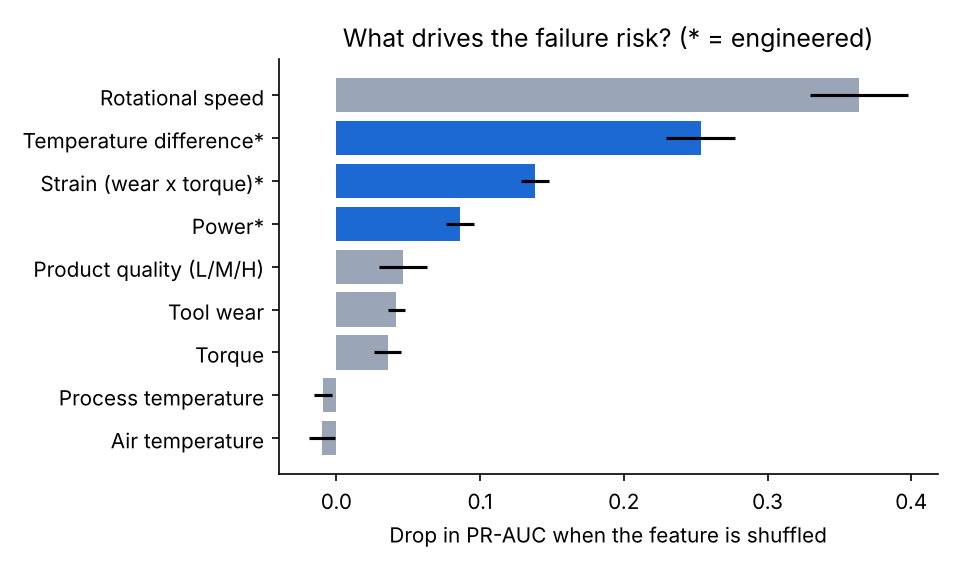

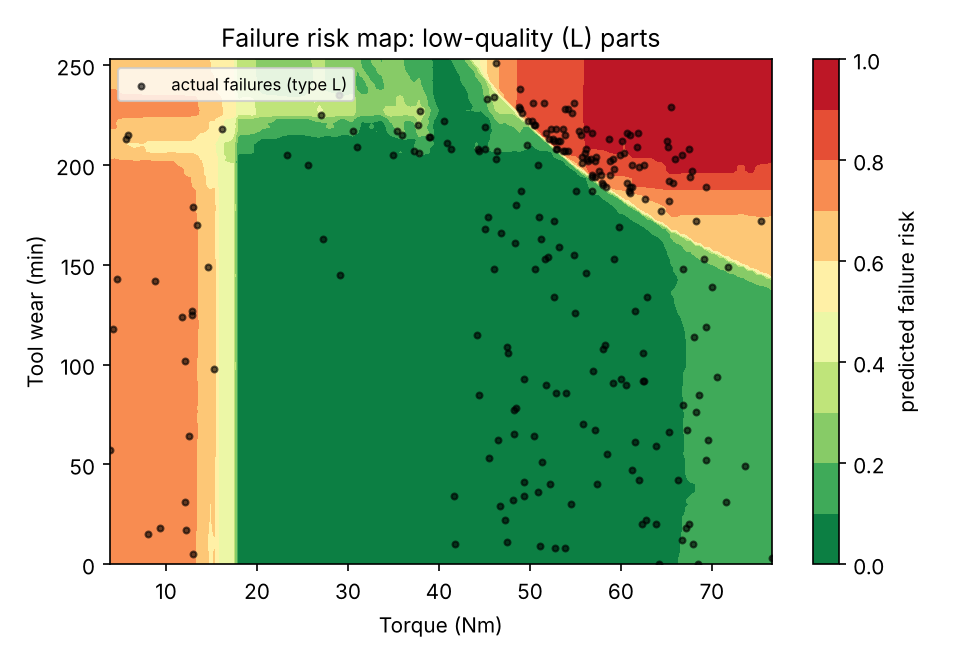

In [12]:
display(Image('assets/feature_importance.png', width=620)); display(Image('assets/failure_map.png', width=620))

## Part 2: Early warning from a temperature sensor

In [13]:
!python src/anomaly_detection.py

22,683 readings, 2013-12-02 21:15:00 to 2014-02-19 15:25:00; calibration week ends 2013-12-09 21:15:00

        detector events_detected  median_warning_hours  false_alarm_events  false_alarms_per_week
    Static limit             4/4                  17.4                   5                    0.5
 Rolling z-score             3/4                   5.4                  31                    3.0
Isolation Forest             3/4                   7.1                  13                    1.3

        detector             event  detected  warning_hours_before_label
    Static limit 11 Dec 2013 06:00      True                        23.6
    Static limit 16 Dec 2013 17:25      True                        12.0
    Static limit 28 Jan 2014 13:55      True                         0.6
    Static limit 08 Feb 2014 14:30      True                        22.8
 Rolling z-score 11 Dec 2013 06:00      True                         5.4
 Rolling z-score 16 Dec 2013 17:25      True                     

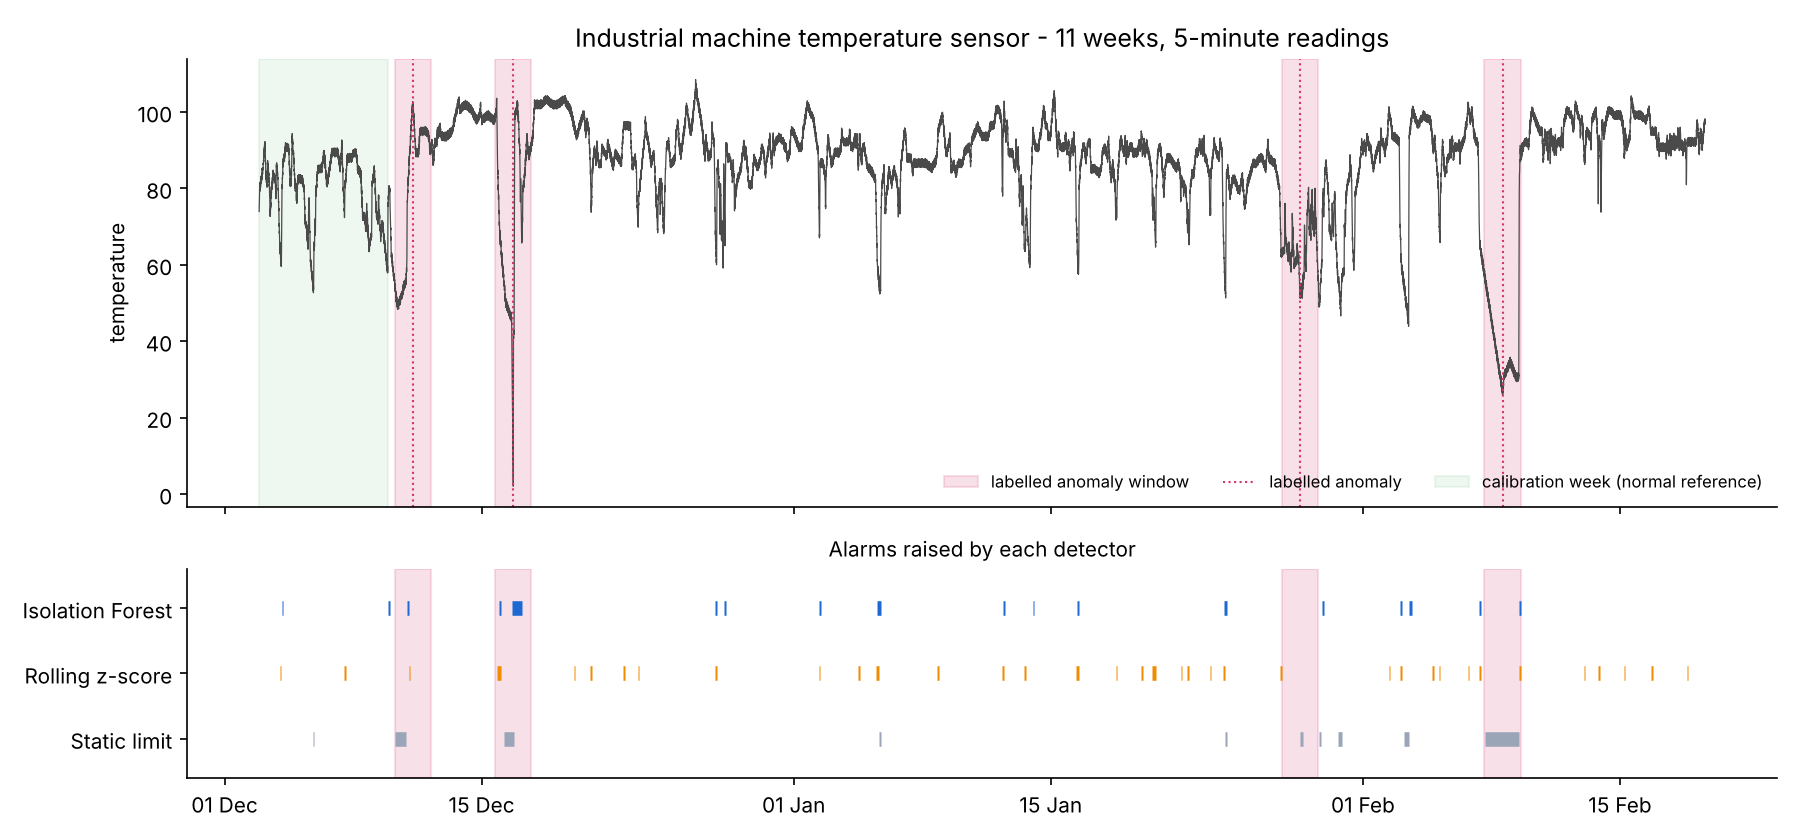

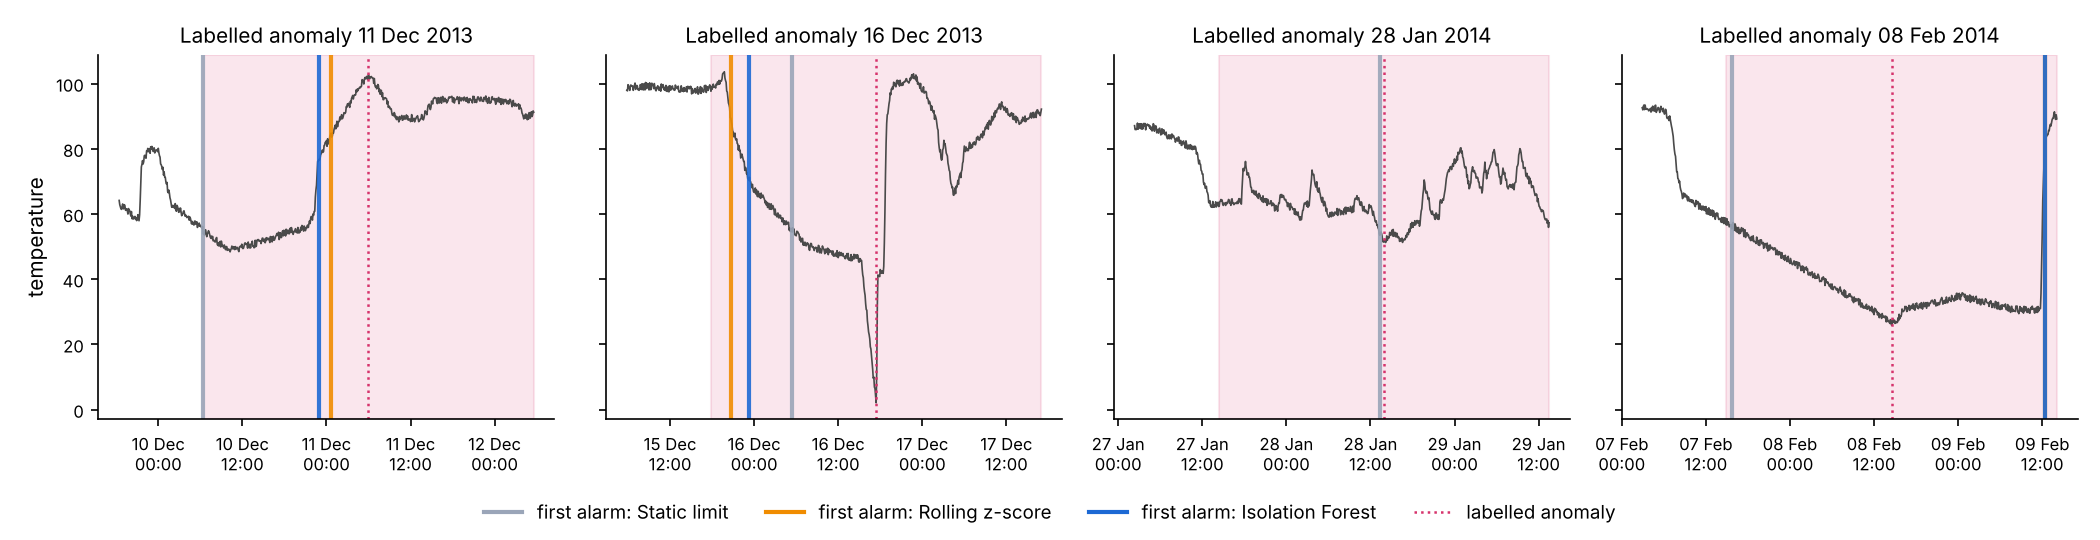

In [14]:
display(Image('assets/anomaly_timeline.png')); display(Image('assets/anomaly_zoom.png'))

**The simplest detector wins on this machine.** A static low-temperature limit, calibrated on one normal week, caught all four labelled events with a median of ~17 hours' warning and the fewest false alarms. The adaptive detectors (rolling z-score, Isolation Forest) react faster to *sudden* changes (16 Dec), but they "get used to" a *slow* decline: they only flagged the 8 Feb failure when the machine restarted, almost a day late.

Lesson: always benchmark ML against the simple rule, and match the detector to how the failure develops.

## Conclusions
- Sensor-based failure prediction catches **85% of failures with 8 false alarms in 2,000 runs** and cuts illustrative maintenance cost by about **two-thirds** vs. running to failure.
- **Physics-based features** matter more than model choice.
- The best **threshold is a business decision**: with the planned tool change, recall rises to 94%, and this pays off once a breakdown costs more than ~EUR 10,750.
- For unlabelled sensor streams, **simple, well-calibrated rules can beat ML**. Combining a static limit with an adaptive detector is the natural next step.